# FireRisk AI — Etapa 2: Modelagem e Inteligência de Negócio

Nesta etapa, uso a **base corrigida da Etapa 1**, com 18.855 registros que possuem pelo menos alguma informação meteorológica.

O objetivo continua sendo prever `fire_occurrence`, onde `1` representa pelo menos um foco de queimada no município naquele dia.

Foram treinados três modelos:

1. Regressão Logística;
2. Random Forest;
3. LightGBM.

As metas definidas previamente são: **Recall ≥ 0,70; F1 ≥ 0,40; Precision ≥ 0,30; ROC-AUC ≥ 0,75; FNR ≤ 0,30**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
from lightgbm import LGBMClassifier

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'processed' / 'dataset_ml.csv').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dataset_ml.csv'
print('Raiz do projeto:', PROJECT_ROOT)
print('Base:', DATA_PATH)

Raiz do projeto: /mnt/data/projeto_final_queimadas_etapa2_corrigido
Base: /mnt/data/projeto_final_queimadas_etapa2_corrigido/data/processed/dataset_ml.csv


## 1. Carregamento e auditoria rápida

A base processada é a mesma aprovada após as correções da Etapa 1. Não uso `focos_queimada` como feature porque essa coluna define diretamente o alvo e causaria *data leakage*.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['data'])
print('Dimensão:', df.shape)
print('Municípios:', df['id_municipio'].nunique())
print('Período:', df['data'].min().date(), 'até', df['data'].max().date())
print('Taxa positiva:', round(df['fire_occurrence'].mean()*100, 2), '%')
df.head()

Dimensão: (18855, 52)
Municípios: 457
Período: 2025-01-01 até 2025-02-12
Taxa positiva: 15.3 %


,data,id_municipio,id_municipio_nome,sigla_uf,sigla_uf_nome,regiao,precipitacao_diaria,pressao_media,radiacao_global_diaria,temperatura_media,temperatura_maxima,temperatura_minima,umidade_media,rajada_maxima,vento_medio,latitude,longitude,altitude,n_estacoes,mb_area_id0_sem_legenda,mb_area_formacao_florestal,mb_area_formacao_savanica,mb_area_mangue,mb_area_silvicultura,mb_area_campo_alagado_area_pantanosa,mb_area_formacao_campestre,mb_area_outras_formacoes_nao_florestais,mb_area_pastagem,mb_area_cana,mb_area_mosaico_de_usos,mb_area_praia_duna_areal,mb_area_area_urbanizada,mb_area_outras_areas_nao_vegetadas,mb_area_afloramento_rochoso,mb_area_mineracao,mb_area_aquicultura,mb_area_apicum,mb_area_rio_lago_oceano,mb_area_soja,mb_area_arroz_beta,mb_area_outras_lavouras_temporarias,mb_area_cafe,mb_area_citrus,mb_area_outras_lavouras_perenes,mb_area_restinga_arborizada,mb_area_restinga_herbacea,mb_area_algodao_beta,mes,dia_do_ano,dia_semana,focos_queimada,fire_occurrence
0,2025-01-01,1100049,Cacoal,RO,Rondônia,Norte,0.2,988.087500,11785.6,25.425000,28.1,23.2,82.916667,7.7,1.858333,-11.445837,-61.434146,183.53,1,0.000000,1415.137698,23.899766,0.0,0.000000,1.083933,5.291485,0.0,2292.183663,0.0,0.000000,0.0,26.546066,0.000000,0.0,0.000000,0.0,0.0,11.324954,14.171178,0.0,3.292101,0.0,0.0,0.0,0.0,0.0,0.0,1,1,2,0,0
1,2025-01-01,1100205,Porto Velho,RO,Rondônia,Norte,0.0,998.500000,2541.1,26.233333,27.4,25.5,82.000000,NaN,NaN,-8.793611,-63.845833,86.70,1,0.010575,22316.670988,29.122937,0.0,0.000000,118.617940,443.801374,0.0,9841.032860,0.0,0.000000,0.0,130.528716,0.000000,0.0,25.440080,0.0,0.0,997.146958,79.713982,0.0,95.353515,0.0,0.0,0.0,0.0,0.0,0.0,1,1,2,0,0
2,2025-01-01,1100304,Vilhena,RO,Rondônia,Norte,0.0,944.579167,16267.1,24.058333,28.9,22.2,83.875000,NaN,NaN,-12.735000,-60.157778,583.30,1,0.000000,8853.127274,777.086174,0.0,7.658729,13.789907,165.539266,0.0,1327.089550,0.0,18.712788,0.0,42.775278,25.972141,0.0,0.820284,0.0,0.0,6.342785,405.615685,0.0,54.662657,0.0,0.0,0.0,0.0,0.0,0.0,1,1,2,0,0
3,2025-01-01,1200252,Epitaciolândia,AC,Acre,Norte,NaN,983.433333,13966.9,25.862500,31.4,23.6,NaN,7.4,0.704167,-11.023889,-68.735278,224.50,1,0.000878,777.859468,0.183543,0.0,0.000000,0.104505,4.395727,0.0,860.538834,0.0,0.000000,0.0,3.213091,0.000000,0.0,0.000000,0.0,0.0,3.970026,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1,1,2,0,0
4,2025-01-01,1200302,Feijó,AC,Acre,Norte,0.0,990.745833,NaN,25.375000,29.4,23.4,79.615385,6.9,1.337500,-8.142654,-70.343594,157.17,1,0.003523,26532.241506,0.812702,0.0,0.000000,9.812763,36.056464,0.0,1296.616395,0.0,0.000000,0.0,4.178743,0.000000,0.0,0.000000,0.0,0.0,83.862147,0.000000,0.0,0.011498,0.0,0.0,0.0,0.0,0.0,0.0,1,1,2,2,1


## 2. Engenharia de atributos e cuidados contra memorização

O município não entra como ID ou nome no modelo. Mantive geografia em nível contínuo (`latitude`, `longitude`, `altitude`) e UF/região porque são informações disponíveis antes da previsão.

Para MapBiomas, transformei as áreas brutas em **proporções de cobertura**, além do log da área total. Isso reduz a chance de o modelo usar somente o tamanho do município como proxy.

A classe MapBiomas de ID 0, que ficou sem legenda oficial na Etapa 1, não é usada no modelo.

In [3]:
mb_raw = [c for c in df.columns if c.startswith('mb_area_') and c != 'mb_area_id0_sem_legenda']
model_df = df.copy()
model_df['mb_total_area'] = model_df[mb_raw].sum(axis=1, min_count=1)
for c in mb_raw:
    model_df[c.replace('mb_area_', 'mb_share_')] = np.where(
        model_df['mb_total_area'] > 0,
        model_df[c] / model_df['mb_total_area'],
        np.nan
    )
model_df['mb_log_total_area'] = np.log1p(model_df['mb_total_area'])

weather = ['precipitacao_diaria','pressao_media','radiacao_global_diaria','temperatura_media','temperatura_maxima','temperatura_minima','umidade_media','rajada_maxima','vento_medio']
mb_share = [c.replace('mb_area_', 'mb_share_') for c in mb_raw]
numeric_features = weather + ['latitude','longitude','altitude','mb_log_total_area','mes','dia_do_ano','dia_semana'] + mb_share
categorical_features = ['sigla_uf','regiao']
feature_cols = numeric_features + categorical_features

print('Número de features antes do one-hot:', len(feature_cols))

Número de features antes do one-hot: 45


## 3. Divisão temporal

Em vez de uma divisão aleatória, usei datas futuras como validação e teste. Isso representa melhor o uso real: aprender com o passado e prever dias posteriores.

- Treino: primeiros 28 dias;
- Validação: 7 dias seguintes;
- Teste: últimos 8 dias.

O conjunto de teste não participa da escolha do modelo nem do threshold.

In [4]:
dates = np.array(sorted(model_df['data'].unique()))
train_dates, valid_dates, test_dates = dates[:28], dates[28:35], dates[35:]
train = model_df[model_df['data'].isin(train_dates)].copy()
valid = model_df[model_df['data'].isin(valid_dates)].copy()
test = model_df[model_df['data'].isin(test_dates)].copy()

X_train, y_train = train[feature_cols], train['fire_occurrence']
X_valid, y_valid = valid[feature_cols], valid['fire_occurrence']
X_test, y_test = test[feature_cols], test['fire_occurrence']

for nome, part in [('Treino',train),('Validação',valid),('Teste',test)]:
    print(nome, part['data'].min().date(), 'a', part['data'].max().date(), '| linhas:', len(part), '| positivos:', int(part['fire_occurrence'].sum()), '| taxa:', round(part['fire_occurrence'].mean(),3))

Treino 2025-01-01 a 2025-01-28 | linhas: 12342 | positivos: 1954 | taxa: 0.158
Validação 2025-01-29 a 2025-02-04 | linhas: 3046 | positivos: 392 | taxa: 0.129
Teste 2025-02-05 a 2025-02-12 | linhas: 3467 | positivos: 539 | taxa: 0.155


## 4. Pré-processamento

Valores ausentes são imputados **dentro da pipeline**, usando apenas estatísticas aprendidas no treino. Isso evita vazamento de informação.

- numéricas: mediana;
- categóricas: moda + one-hot;
- Regressão Logística: também recebe padronização;
- os modelos usam ponderação de classes devido ao desbalanceamento.

In [5]:
num_pre = Pipeline([('imputer', SimpleImputer(strategy='median'))])
cat_pre = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('num', num_pre, numeric_features),
    ('cat', cat_pre, categorical_features)
])
preprocessor_scaled = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler())
])

models = {
    'Regressão Logística': Pipeline([
        ('prep', clone(preprocessor_scaled)),
        ('model', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('prep', clone(preprocessor)),
        ('model', RandomForestClassifier(n_estimators=400, min_samples_leaf=2, max_features='sqrt', class_weight='balanced_subsample', random_state=42, n_jobs=-1))
    ]),
    'LightGBM': Pipeline([
        ('prep', clone(preprocessor)),
        ('model', LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, class_weight='balanced', random_state=42, n_jobs=-1, verbosity=-1))
    ])
}

In [6]:
def avaliar(model, X, y, threshold=0.5):
    prob = model.predict_proba(X)[:,1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        'acuracia': accuracy_score(y,pred),
        'precisao': precision_score(y,pred,zero_division=0),
        'recall': recall_score(y,pred,zero_division=0),
        'f1_score': f1_score(y,pred,zero_division=0),
        'roc_auc': roc_auc_score(y,prob),
        'false_negative_rate': fn/(fn+tp),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }

rows=[]
for nome, model in models.items():
    model.fit(X_train, y_train)
    rows.append({'modelo':nome, **avaliar(model,X_test,y_test,0.50)})

resultados = pd.DataFrame(rows)
resultados.round(3)

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,modelo,acuracia,precisao,recall,f1_score,roc_auc,false_negative_rate,TN,FP,FN,TP
0,Regressão Logística,0.662,0.288,0.796,0.422,0.790,0.204,1865,1063,110,429
1,Random Forest,0.845,0.504,0.343,0.408,0.796,0.657,2746,182,354,185
2,LightGBM,0.785,0.385,0.642,0.482,0.809,0.358,2376,552,193,346


## 5. Comparação dos três modelos

Resultados reais obtidos no conjunto de teste com threshold padrão de 0,50:

| Modelo | Acurácia | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Regressão Logística | 0.662 | 0.288 | **0.796** | 0.422 | 0.790 |
| Random Forest | **0.845** | **0.504** | 0.343 | 0.408 | 0.796 |
| LightGBM | 0.785 | 0.385 | 0.642 | **0.482** | **0.809** |

Um baseline que prevê sempre `0` teria acurácia de **0.845** e recall zero. Isso confirma que acurácia sozinha é enganosa neste problema.

O LightGBM foi escolhido para continuidade porque apresentou o melhor equilíbrio, com maior F1 e ROC-AUC.

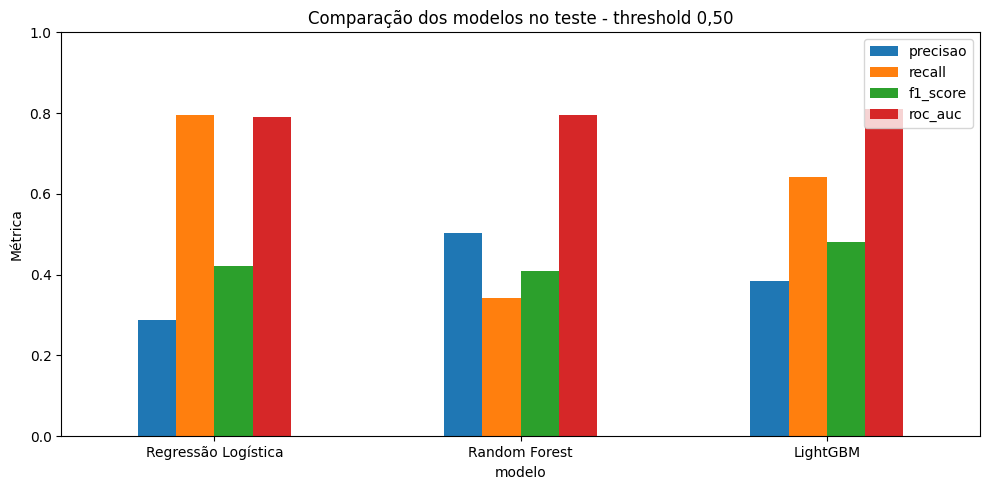

In [7]:
resultados.set_index('modelo')[['precisao','recall','f1_score','roc_auc']].plot(kind='bar', figsize=(10,5))
plt.ylim(0,1)
plt.ylabel('Métrica')
plt.title('Comparação dos modelos no teste - threshold 0,50')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Ajuste do threshold no conjunto de validação

Com threshold 0,50, o LightGBM ainda não atingia a meta de recall ≥ 0,70. Por isso, ajustei **somente o limiar de decisão**, sem otimizar hiperparâmetros (isso fica para a Etapa 3).

O limiar foi escolhido usando apenas a validação. O valor **0,42** fornece margem de recall acima da meta na validação sem reduzir precision abaixo de 0,30.

In [8]:
lgbm = models['LightGBM']
prob_valid = lgbm.predict_proba(X_valid)[:,1]
threshold_rows=[]
for th in np.round(np.arange(0.10,0.81,0.01),2):
    pred=(prob_valid>=th).astype(int)
    threshold_rows.append({
        'threshold':th,
        'precision':precision_score(y_valid,pred,zero_division=0),
        'recall':recall_score(y_valid,pred,zero_division=0),
        'f1':f1_score(y_valid,pred,zero_division=0)
    })
threshold_table=pd.DataFrame(threshold_rows)
threshold_table[(threshold_table['threshold']>=0.38)&(threshold_table['threshold']<=0.46)].round(3)

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,threshold,precision,recall,f1
28,0.38,0.327,0.758,0.457
29,0.39,0.331,0.753,0.460
30,0.40,0.331,0.737,0.457
31,0.41,0.336,0.727,0.460
32,0.42,0.343,0.724,0.465
33,0.43,0.347,0.719,0.468
34,0.44,0.351,0.712,0.470
35,0.45,0.351,0.704,0.469
36,0.46,0.354,0.689,0.468


In [9]:
operational_threshold = 0.42
final_metrics = avaliar(lgbm, X_test, y_test, operational_threshold)
pd.DataFrame([final_metrics], index=['LightGBM threshold 0,42']).round(3)

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,acuracia,precisao,recall,f1_score,roc_auc,false_negative_rate,TN,FP,FN,TP
"LightGBM threshold 0,42",0.751,0.349,0.701,0.466,0.809,0.299,2224,704,161,378


### Resultado final do modelo selecionado

No conjunto de teste, o LightGBM com threshold **0,42** obteve:

- **Precision:** 0.349
- **Recall:** 0.701
- **F1-score:** 0.466
- **ROC-AUC:** 0.809
- **False Negative Rate:** 0.299

Com isso, o modelo atende às cinco metas estabelecidas na Etapa 1. A acurácia cai em relação ao Random Forest, mas isso é esperado porque estamos priorizando não perder ocorrências reais.

In [10]:
kpis = pd.DataFrame([
    ['Recall', final_metrics['recall'], 0.70, final_metrics['recall'] >= 0.70],
    ['F1-score', final_metrics['f1_score'], 0.40, final_metrics['f1_score'] >= 0.40],
    ['Precision', final_metrics['precisao'], 0.30, final_metrics['precisao'] >= 0.30],
    ['ROC-AUC', final_metrics['roc_auc'], 0.75, final_metrics['roc_auc'] >= 0.75],
    ['False Negative Rate', final_metrics['false_negative_rate'], 0.30, final_metrics['false_negative_rate'] <= 0.30],
], columns=['KPI','Resultado','Meta','Meta atingida'])
kpis

,KPI,Resultado,Meta,Meta atingida
0,Recall,0.701299,0.70,True
1,F1-score,0.466379,0.40,True
2,Precision,0.349353,0.30,True
3,ROC-AUC,0.809189,0.75,True
4,False Negative Rate,0.298701,0.30,True


## 7. Impacto financeiro

A base não contém custo real de incêndio nem custo de mobilização. Portanto, os valores abaixo são **cenários ilustrativos**, não economias comprovadas.

A lógica compara:

- sem modelo: todo evento positivo seria tratado como não antecipado;
- com modelo: custo dos falsos negativos + custo dos falsos positivos.

A função fica parametrizada para receber os valores reais quando o cliente disponibilizar esses dados.

In [11]:
def calcular_impacto(fp, fn, total_positivos, custo_fn=50000, custo_fp=2000):
    custo_sem_modelo = total_positivos * custo_fn
    custo_com_modelo = fn * custo_fn + fp * custo_fp
    economia = custo_sem_modelo - custo_com_modelo
    return {
        'custo_sem_modelo_R$': custo_sem_modelo,
        'custo_com_modelo_R$': custo_com_modelo,
        'economia_estimada_R$': economia,
        'reducao_custo_pct': 100 * economia / custo_sem_modelo
    }

impacto = calcular_impacto(
    fp=int(final_metrics['FP']),
    fn=int(final_metrics['FN']),
    total_positivos=int(y_test.sum()),
    custo_fn=50000,
    custo_fp=2000
)
pd.DataFrame([impacto], index=['Cenário base ilustrativo'])

,custo_sem_modelo_R$,custo_com_modelo_R$,economia_estimada_R$,reducao_custo_pct
Cenário base ilustrativo,26950000,9458000,17492000,64.90538


No cenário ilustrativo de R$ 50 mil por evento não antecipado e R$ 2 mil por falso alerta, o LightGBM operacional gera uma economia estimada de **R$ 17,492,000** no recorte de teste.

O número serve para demonstrar a lógica exigida pelo projeto. Antes de usar esse valor em uma decisão real, os custos precisam ser substituídos por dados financeiros do negócio.

## 8. Teste de robustez geográfica

Na avaliação da Etapa 1 surgiu uma preocupação importante: geografia e MapBiomas são constantes por município. Para verificar se o modelo apenas memoriza localidades, fiz um teste adicional separando **municípios que nunca aparecem no treino**.

Este teste não substitui a validação temporal e não foi usado para selecionar o modelo; ele serve apenas como análise de robustez.

In [12]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
idx_train_g, idx_test_g = next(gss.split(model_df, model_df['fire_occurrence'], groups=model_df['id_municipio']))
geo_train = model_df.iloc[idx_train_g]
geo_test = model_df.iloc[idx_test_g]

geo_model = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, class_weight='balanced', random_state=42, n_jobs=-1, verbosity=-1))
])
geo_model.fit(geo_train[feature_cols], geo_train['fire_occurrence'])
geo_metrics = avaliar(geo_model, geo_test[feature_cols], geo_test['fire_occurrence'], 0.42)
print('Municípios de treino:', geo_train['id_municipio'].nunique())
print('Municípios não vistos no teste:', geo_test['id_municipio'].nunique())
pd.DataFrame([geo_metrics]).round(3)

Municípios de treino: 365
Municípios não vistos no teste: 92


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,acuracia,precisao,recall,f1_score,roc_auc,false_negative_rate,TN,FP,FN,TP
0,0.748,0.382,0.746,0.505,0.821,0.254,2385,803,169,496


No teste com **92 municípios não vistos**, o modelo apresentou Recall de **0.746**, Precision de **0.382**, F1 de **0.505** e ROC-AUC de **0.821**.

O resultado indica que o modelo consegue generalizar para localidades não vistas e reduz a preocupação de simples memorização do município. Ainda assim, a janela temporal de 43 dias continua sendo uma limitação importante.

## 9. Plano do teste A/B

### Hipótese
O uso dos alertas do modelo reduz eventos não antecipados sem gerar um volume operacional inviável de falsos alertas.

### Grupos
- **Controle:** processo atual, sem alerta do modelo.
- **Tratamento:** processo atual + alerta FireRisk AI.

### Unidade de randomização
Município ou unidade operacional. Recomendo estratificar antes por região e faixa histórica de risco.

### KPI primário
Percentual de eventos reais antecipados.

### KPIs secundários
Falsos negativos, falsos positivos, tempo de resposta, custo por alerta, custo total e percentual de alertas considerados acionáveis.

### Critério de sucesso
O tratamento deve reduzir eventos não antecipados e custo total sem ultrapassar um limite operacional previamente acordado de falsos alertas.

O tamanho amostral deve ser calculado antes do experimento com alfa de 5%, poder de 80%, taxa histórica de ocorrência e efeito mínimo relevante.

## 10. Conclusão da Etapa 2

Nesta etapa, comparei três modelos usando uma divisão temporal para evitar que dados futuros participassem do treinamento.

A Regressão Logística conseguiu identificar mais queimadas, mas gerou muitos falsos alertas. O Random Forest teve a maior acurácia, porém perdeu muitos eventos positivos. O LightGBM apresentou o melhor equilíbrio entre as métricas e foi escolhido para continuar o projeto.

Depois da escolha, ajustei apenas o threshold usando a validação. Com threshold 0,42, o LightGBM atingiu as metas definidas anteriormente, inclusive Recall acima de 0,70 e FNR abaixo de 0,30 no conjunto de teste.

Também criei uma função de impacto financeiro, deixando claro que os valores usados são cenários ilustrativos, e um plano de teste A/B para validar o valor do modelo em operação.

Por fim, testei o LightGBM em municípios não vistos no treinamento. O desempenho permaneceu consistente, o que é um sinal positivo contra a hipótese de que o modelo esteja apenas memorizando localidades.

Na Etapa 3, o próximo passo é otimizar o LightGBM com Optuna, usar SHAP para explicar as previsões e analisar possíveis diferenças de desempenho por região e outros grupos.